# Métricas de la trivia — Robot Romeo
**Sesión 8 nov 2026 · captura con `ROMEO_MEDIR=1`**

Solo métricas de la **trivia**. Este notebook lee los CSV crudos y genera las gráficas.

**Nodos del sistema:** `communication_node` (STT+TTS) · `expression_faces_node` (FER+caras) · `moving_control_node` (carrito) · `orchestrator_node` (afectiva PULSE/ROSE/AEB + LLM + trivia).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
    "axes.spines.right": False, "font.family": "DejaVu Sans",
})
GRIS="#2b3a52"; VERDE="#1ba378"; NARANJA="#e07a1a"; AZUL="#2a78d6"; ROJO="#c0392b"

BASE = Path(r".")   # misma carpeta del notebook
def ruta(n): return BASE / n

## 1. Cargar los datos

In [2]:
# turnos (Pi): afectiva + LLM + tokens
filas = []
with open(ruta("turnos.csv"), encoding="utf-8", errors="replace") as f:
    next(f)
    for ln in f:
        nums=[]
        for x in ln.split(","):
            try: nums.append(float(x))
            except ValueError: pass
        if len(nums) < 4: continue
        ei = next((i for i,v in enumerate(nums) if v > 1e9), None)
        if ei is None or ei < 3: continue
        t_llm=nums[ei-1]; tok=nums[ei-3]; afect=nums[0]*1000
        if 50 <= t_llm <= 5000 and 1 <= tok <= 200:
            filas.append({"t_llm_ms":t_llm,"tokens_salida":tok,
                          "afectiva_ms": afect if afect < 3000 else np.nan})
turnos = pd.DataFrame(filas)
mod = pd.read_csv(ruta("modulos_pc.csv"))
tts = pd.read_csv(ruta("tts.csv"))
sis = pd.read_csv(ruta("sistema.csv"))
sis["min"] = (sis["t"] - sis["t"].iloc[0]) / 60
print("turnos:", len(turnos), "| modulos:", len(mod), "| tts:", len(tts), "| sistema:", len(sis))

turnos: 32 | modulos: 34 | tts: 65 | sistema: 319


## 2. Comparación Rocha vs IA  —  ¿coincide la respuesta?

Para cada pregunta de la trivia, la respuesta **generada por el LLM** se compara con la **respuesta por defecto de Rocha** (del banco de preguntas). Un LLM juez decide si coinciden. Por categoría.

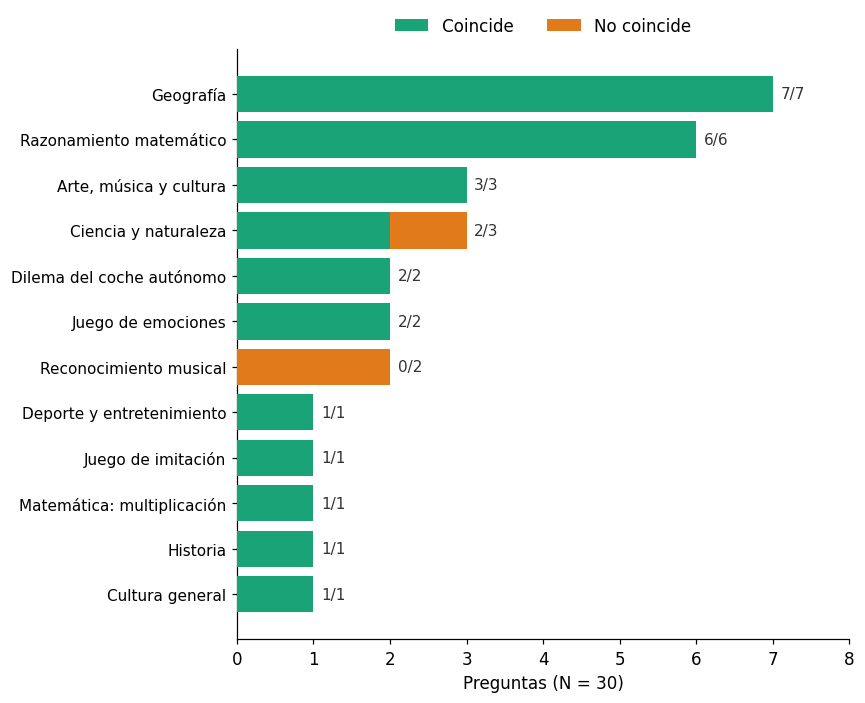

Coincidencia Rocha vs IA: 27/30 = 90%


In [3]:
# Datos de la comparacion Coincide / No coincide (27/30 = 90%)
cats = [
    ("Geografía",7,7),("Razonamiento matemático",6,6),("Arte, música y cultura",3,3),
    ("Ciencia y naturaleza",2,3),("Dilema del coche autónomo",2,2),("Juego de emociones",2,2),
    ("Reconocimiento musical",0,2),("Deporte y entretenimiento",1,1),("Juego de imitación",1,1),
    ("Matemática: multiplicación",1,1),("Historia",1,1),("Cultura general",1,1),
]
dfc = pd.DataFrame(cats, columns=["categoria","coincide","total"])
dfc["no_coincide"] = dfc["total"] - dfc["coincide"]
dfc = dfc.iloc[::-1].reset_index(drop=True)  # orden como el ejemplo (mayor arriba)

fig, ax = plt.subplots(figsize=(8,6.5))
y = np.arange(len(dfc))
ax.barh(y, dfc["coincide"], color=VERDE, zorder=3, label="Coincide")
ax.barh(y, dfc["no_coincide"], left=dfc["coincide"], color=NARANJA, zorder=3, label="No coincide")
for i,(c,t) in enumerate(zip(dfc["coincide"], dfc["total"])):
    ax.text(t+0.1, i, f"{c}/{t}", va="center", fontsize=10, color="#333")
ax.set_yticks(y); ax.set_yticklabels(dfc["categoria"], fontsize=10)
co, to = dfc["coincide"].sum(), dfc["total"].sum()
ax.set_xlabel(f"Preguntas (N = {to})")
ax.legend(loc="upper center", bbox_to_anchor=(0.5,1.08), ncol=2, frameon=False, fontsize=11)
ax.set_xlim(0, dfc["total"].max()+1)
plt.tight_layout(); plt.show()
print(f"Coincidencia Rocha vs IA: {co}/{to} = {100*co/to:.0f}%")

## 3. Latencia por módulo (trivia)

Tiempo promedio de cada etapa del turno de trivia. FER corre en el sensor IMX500 (no cronometrable como CPU): se reporta como la ventana de percepción. PULSE+ROSE+AEB se miden como un bloque (la capa afectiva es aritmética, <1 ms).

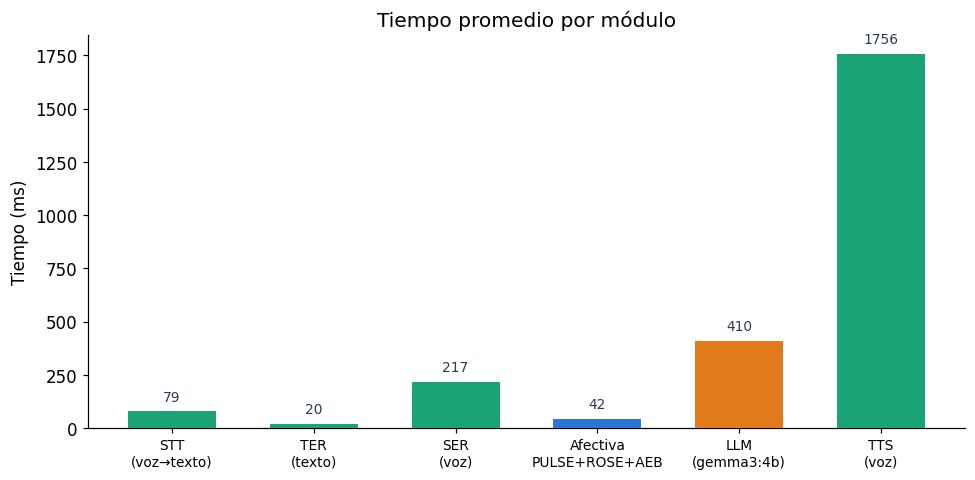

In [4]:
def prom(s):
    s = pd.to_numeric(s, errors="coerce").dropna()
    return s.mean() if len(s) else np.nan

mods = {
    "STT\n(voz→texto)": mod["t_stt_ms"],
    "TER\n(texto)":     mod["t_ter_ms"],
    "SER\n(voz)":       mod["t_ser_ms"],
    "Afectiva\nPULSE+ROSE+AEB": turnos["afectiva_ms"],
    "LLM\n(gemma3:4b)": turnos["t_llm_ms"],
    "TTS\n(voz)":       tts["t_tts_ms"],
}
cols = [VERDE,VERDE,VERDE,AZUL,NARANJA,VERDE]
vals = [prom(s) for s in mods.values()]

fig, ax = plt.subplots(figsize=(9,4.5))
x = np.arange(len(mods))
ax.bar(x, vals, color=cols, width=0.62, zorder=3)
for i,v in enumerate(vals):
    ax.text(i, v+max(vals)*0.02, f"{v:.0f}", ha="center", va="bottom", fontsize=9, color=GRIS)
ax.set_xticks(x); ax.set_xticklabels(mods.keys(), fontsize=9)
ax.set_ylabel("Tiempo (ms)")
ax.set_title("Tiempo promedio por módulo")
plt.tight_layout(); plt.show()

## 4. Latencia por nodo

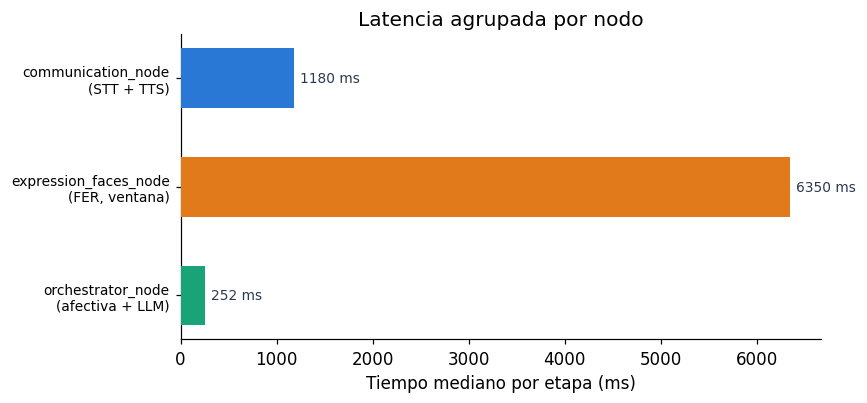

In [5]:
import re
fer = []
try:
    log = open(ruta("romeo_run.log"), encoding="utf-8", errors="replace").read()
    fer = [float(m.group(1)) for m in re.finditer(r"FER: \d+ cuadros en ([\d.]+) s", log)]
except FileNotFoundError:
    pass
fer_med = np.median(fer)*1000 if fer else np.nan

nodos = {
    "communication_node\n(STT + TTS)": prom(pd.concat([mod["t_stt_ms"], tts["t_tts_ms"]])),
    "expression_faces_node\n(FER, ventana)": fer_med,
    "orchestrator_node\n(afectiva + LLM)": prom(pd.concat([turnos["afectiva_ms"], turnos["t_llm_ms"]])),
}
fig, ax = plt.subplots(figsize=(8,3.8))
y = np.arange(len(nodos)); vals=list(nodos.values())
ax.barh(y, vals, color=[AZUL,NARANJA,VERDE], height=0.55, zorder=3)
for i,v in enumerate(vals):
    ax.text(v+max(vals)*0.01, i, f"{v:.0f} ms", va="center", fontsize=9, color=GRIS)
ax.set_yticks(y); ax.set_yticklabels(nodos.keys(), fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("Tiempo mediano por etapa (ms)")
ax.set_title("Latencia agrupada por nodo")
plt.tight_layout(); plt.show()

## 5. Tokens del LLM

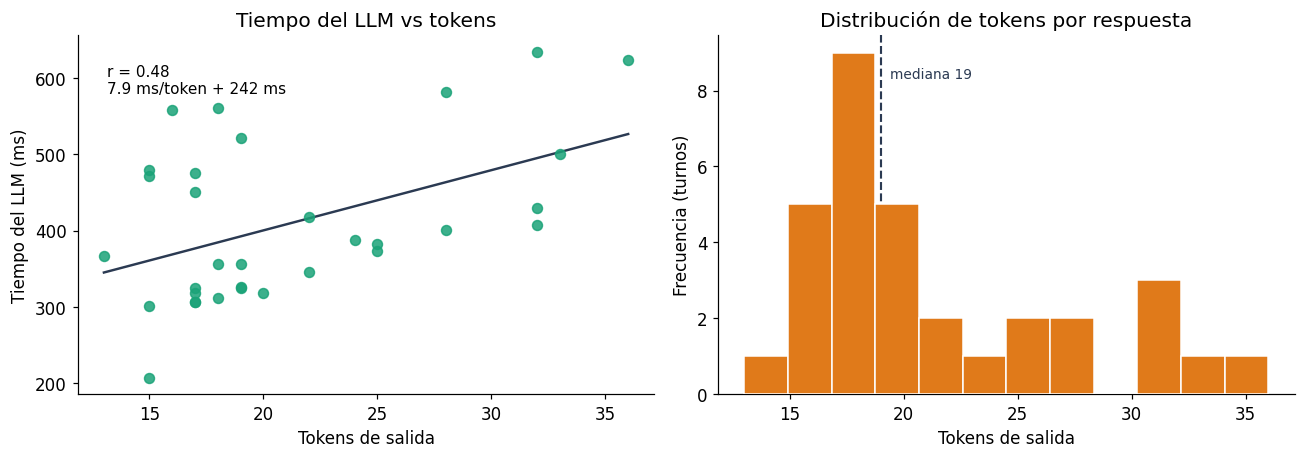

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12,4.3))
x = turnos["tokens_salida"].values; yv = turnos["t_llm_ms"].values
axs[0].scatter(x, yv, color=VERDE, s=42, alpha=0.85, zorder=3)
if len(x) > 2:
    b,a = np.polyfit(x,yv,1); xs=np.array([x.min(),x.max()])
    axs[0].plot(xs, a+b*xs, color=GRIS, lw=1.6)
    r = np.corrcoef(x,yv)[0,1]
    axs[0].text(0.05,0.92,f"r = {r:.2f}\n{b:.1f} ms/token + {a:.0f} ms",
                transform=axs[0].transAxes, va="top", fontsize=10)
axs[0].set_xlabel("Tokens de salida"); axs[0].set_ylabel("Tiempo del LLM (ms)")
axs[0].set_title("Tiempo del LLM vs tokens")
axs[1].hist(x, bins=12, color=NARANJA, zorder=3, edgecolor="white")
axs[1].axvline(np.median(x), color=GRIS, lw=1.4, ls="--")
axs[1].text(np.median(x)+0.4, axs[1].get_ylim()[1]*0.88, f"mediana {np.median(x):.0f}", fontsize=9, color=GRIS)
axs[1].set_xlabel("Tokens de salida"); axs[1].set_ylabel("Frecuencia (turnos)")
axs[1].set_title("Distribución de tokens por respuesta")
plt.tight_layout(); plt.show()

## 6. Recursos de la Raspberry Pi (de inicio a fin)

CPU total, proceso de cámara (FER), temperatura y RAM durante la sesión.

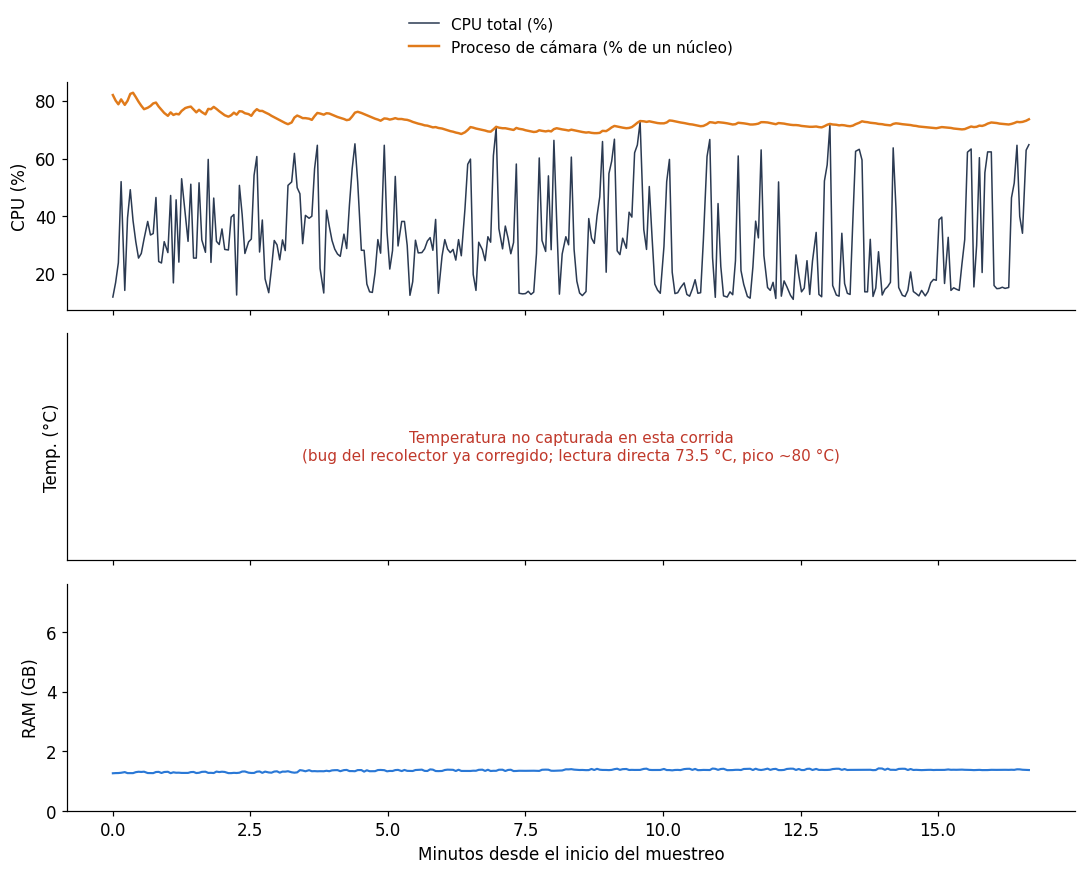

Recursos:
  CPU total:  mediana 28.5%  max 72.7%
  CPU camara: mediana 72.1%  max 82.8%
  RAM usada:  mediana 1412 MB  max 1468 MB


In [7]:
tiene_temp = (sis["temp_c"] > 0).any()
ram_gb = sis["ram_usada_mb"] / 1024
ram_total_gb = sis["ram_total_mb"].iloc[0]/1024 if "ram_total_mb" in sis.columns else 8

fig, axs = plt.subplots(3, 1, figsize=(10,8), sharex=True)
# (1) CPU total + camara
axs[0].plot(sis["min"], sis["cpu_total_pct"], color=GRIS, lw=1, label="CPU total (%)")
axs[0].plot(sis["min"], sis["cpu_camara_pct"], color=NARANJA, lw=1.6, label="Proceso de cámara (% de un núcleo)")
axs[0].set_ylabel("CPU (%)")
axs[0].legend(loc="upper center", bbox_to_anchor=(0.5,1.35), ncol=1, frameon=False, fontsize=10)
# (2) Temperatura
if tiene_temp:
    axs[1].plot(sis["min"], sis["temp_c"], color=NARANJA, lw=1.3)
    axs[1].axhline(80, color=GRIS, ls="--", lw=1)
    axs[1].text(sis["min"].max(), 80.4, "80 °C", ha="right", fontsize=9, color=GRIS)
    axs[1].set_ylabel("Temp. (°C)")
else:
    axs[1].text(0.5,0.5,"Temperatura no capturada en esta corrida\n(bug del recolector ya corregido; lectura directa 73.5 °C, pico ~80 °C)",
                transform=axs[1].transAxes, ha="center", va="center", fontsize=10, color=ROJO)
    axs[1].set_ylabel("Temp. (°C)"); axs[1].set_yticks([])
# (3) RAM
axs[2].plot(sis["min"], ram_gb, color=AZUL, lw=1.4)
axs[2].set_ylabel("RAM (GB)"); axs[2].set_ylim(0, ram_total_gb)
axs[2].set_xlabel("Minutos desde el inicio del muestreo")
plt.tight_layout(); plt.show()

print("Recursos:")
print(f"  CPU total:  mediana {sis['cpu_total_pct'].median():.1f}%  max {sis['cpu_total_pct'].max():.1f}%")
print(f"  CPU camara: mediana {sis['cpu_camara_pct'].median():.1f}%  max {sis['cpu_camara_pct'].max():.1f}%")
print(f"  RAM usada:  mediana {sis['ram_usada_mb'].median():.0f} MB  max {sis['ram_usada_mb'].max():.0f} MB")

## 7. Tabla resumen (trivia)

In [8]:
def prom1(s):
    s = pd.to_numeric(s, errors="coerce").dropna()
    return round(s.mean(),1) if len(s) else np.nan

tabla = []
for nombre, serie, unidad, nodo in [
    ("STT (voz→texto)", mod["t_stt_ms"], "ms", "communication / PC"),
    ("SER (emoción voz)", mod["t_ser_ms"], "ms", "communication / PC"),
    ("TER (emoción texto)", mod["t_ter_ms"], "ms", "communication / PC"),
    ("Afectiva PULSE+ROSE+AEB", turnos["afectiva_ms"], "ms", "orchestrator / Pi"),
    ("Respuesta LLM", turnos["t_llm_ms"], "ms", "orchestrator / Pi→PC"),
    ("Síntesis TTS", tts["t_tts_ms"], "ms", "communication / PC"),
    ("Tokens de salida", turnos["tokens_salida"], "tokens", "orchestrator"),
    ("CPU total Pi", sis["cpu_total_pct"], "%", "Raspberry"),
    ("CPU cámara/FER", sis["cpu_camara_pct"], "%", "expression / IMX500"),
    ("RAM usada Pi", sis["ram_usada_mb"], "MB", "Raspberry"),
]:
    tabla.append([nombre, prom1(serie), unidad, nodo])
df = pd.DataFrame(tabla, columns=["Indicador","Promedio","Unidad","Nodo / máquina"])
print("Coincidencia Rocha vs IA: 27/30 = 90%\n")
df

Coincidencia Rocha vs IA: 27/30 = 90%



,Indicador,Promedio,Unidad,Nodo / máquina
0,STT (voz→texto),78.6,ms,communication / PC
1,SER (emoción voz),216.8,ms,communication / PC
2,TER (emoción texto),20.0,ms,communication / PC
3,Afectiva PULSE+ROSE+AEB,41.7,ms,orchestrator / Pi
4,Respuesta LLM,410.2,ms,orchestrator / Pi→PC
5,Síntesis TTS,1756.2,ms,communication / PC
6,Tokens de salida,21.2,tokens,orchestrator
7,CPU total Pi,31.4,%,Raspberry
8,CPU cámara/FER,72.7,%,expression / IMX500
9,RAM usada Pi,1397.3,MB,Raspberry
